# FRB population DM distribution - D0 (12m) only

Single-telescope split of `DM_comparison_mc_fluence_DM.ipynb`. The last cell saves the weighted DM distribution to `/home/thsu/FRB_population/DM_distribution`.

In [1]:

from pathlib import Path
import time
import numpy as np
from astropy.cosmology import Planck18 as cosmo
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad, simps, cumtrapz  # ADD cumtrapz HERE
from scipy.optimize import curve_fit
from scipy.special import erf
import sympy as sp
from scipy.stats import gaussian_kde
import matplotlib.patches as mpatches
from astropy.cosmology import Planck18 as cosmo, z_at_value
from astropy import units as u
from scipy.interpolate import interp1d
from astropy.cosmology import FlatLambdaCDM

In [2]:
# ============================================================================
# TELESCOPE SELECTION
# ============================================================================
TELESCOPE = "D0"
# Other options: "Fast", "Meerkat_incoherent", "Meerkat_coherent", "askap_ics", "askap_flyeye"




TELESCOPE_PARAMS = {

    "d0": {
        "D": 13.5,
        "eta": 0.70,
        "Trec": 20,
        "Tsky": 3,
        "BW": 856e6,
        "nu_cen": 1.284e9,
        "n_comp": 16,
        "n_dish": 64,
        "n_chan": 2048,
        "mode": "incoherent",
        "description": "MeerKAT array - incoherent beam (power addition)",
        "tsamp": 306.24e-6,
        "fov": 1.27,
    },

}

In [3]:
alpha_intrinsic = 0  # Fixed intrinsic spectral index

In [4]:

# # EFFECT CONTROL FLAGS
# # ============================================================================
USE_COSMOLOGY = True      # Tozggle Euclidean vs cosmological universe (affects distances, volumes)
USE_SFR = True           
USE_SMEARING = True      
USE_SPECTRAL_INDEX = True 


# USE_COSMOLOGY = False
# USE_SFR = False           
# USE_SMEARING = False    
# USE_SPECTRAL_INDEX = False

USE_BEAM = True
# USE_BEAM = False

# # # Luminosity function parameters
LUMINOSITY_FUNCTION = "schechter"  
# LUMINOSITY_FUNCTION = "std" 

In [5]:


# Load selected telescope
if TELESCOPE.lower() not in TELESCOPE_PARAMS:
    raise ValueError(f"Telescope must be one of: {list(TELESCOPE_PARAMS.keys())}")

params = TELESCOPE_PARAMS[TELESCOPE.lower()]

# Physical constants
k = 1.38e-23
c = 3.0e8

# Extract telescope parameters
D = params["D"]
eta = params["eta"]
# n_dishes = params.get("n_dishes", 1)
# mode = params.get("mode", "single")

# n_beams = params.get("n_beams", 1) if mode != "coherent" and mode != "incoherent" else 1
# array_gain_factor = n_dishes if mode == "coherent" else np.sqrt(n_dishes) if mode == "incoherent" else 1
G0 = np.pi * D*D/4 * eta/2.0/k*1e-26

Np = 2



In [6]:
# ============================================================================
# REDSHIFT PARAMETERS
# ============================================================================
dz = 0.001
z_min = 0.01
z_max = 5.0
z_array_opt = np.arange(z_min, z_max, dz)

# Options: "schechter" or "std"

L_STAR = 1e13  # Characteristic luminosity (Jy·kpc²)
ALPHA_SCH = -1.2  # Faint-end slope
L_MIN_SCH = 1e6
L_MAX_SCH = 1e16

# L_std = 2.4e14  # Jy·kpc²
L_std = 1*1e11  # Jy·kpc²

# Simulation parameters
# theta_max = 2*1.22*c/D/nu_min # please note here
fscale = 100 * 1e-7  # FRB rate scaling factor

SNR_threshold = 8
t_obs = 0.001
TARGET_DETECTIONS = 10  # Target 10 detections per z-bin

# Cosmology
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

np.random.seed(42)


In [7]:
def gaussian_beam_gain(nu, G0, theta, D, c):
    """
    Gaussian beam gain with frequency dependence
    G(ν) = G₀ × exp[−θ²ν²D²×2.355²/(2×1.22²×c²)]
    """
    # Exponent coefficient
    coeff = (theta**2 * D**2 * 2.355**2) / (2 * 1.22**2 * c**2)
    return G0 * np.exp(-coeff * nu**2)

# Pre-calculate constants for speed
_COEFF_CONST = (2.355**2) / (2 * 1.22**2 * (3.0e8**2))

def gaussian_beam_gain_fast(nu_array, G0, theta, D):
    """Optimized version for the inner loop"""
    coeff = theta**2 * D**2 * _COEFF_CONST
    return G0 * np.exp(-coeff * nu_array**2)


def SNR(S,t,G,BW,Np,Trec,Tsky):
    return(S*G*np.sqrt(BW*t*Np)/(Trec+Tsky))

In [8]:
def schechter_function(L, L_star, alpha, phi_star=1.0):
    """
    Schechter luminosity function.
    
    φ(L) = φ* (L/L*)^α * exp(-L/L*)
    
    Parameters:
    -----------
    L : float or array
        Luminosity
    L_star : float
        Characteristic luminosity (knee of the function)
    alpha : float
        Faint-end slope (typically negative)
    phi_star : float
        Normalization constant (default: 1.0)
    
    Returns:
    --------
    phi : float or array
        Number density at luminosity L
    """
    x = L / L_star
    return phi_star * x**alpha * np.exp(-x)

In [9]:
def create_truncated_schechter_sampler(L_min, L_max, L_star, alpha):
    """Create sampler for Schechter function truncated between L_min and L_max"""
    L_grid = np.logspace(np.log10(L_min), np.log10(L_max), 2000)
    phi_grid = schechter_function(L_grid, L_star, alpha)
    
    # REMOVE THIS LINE:
    # from scipy.integrate import cumtrapz
    
    cdf = cumtrapz(phi_grid, L_grid, initial=0)
    cdf = cdf / cdf[-1]
    
    inv_cdf = interp1d(cdf, L_grid, kind='linear', 
                       bounds_error=False, fill_value=(L_min, L_max))
    return inv_cdf

In [10]:

# ============================================================================
# CREATE TRUNCATED SCHECHTER SAMPLER FOR EACH Z
# ============================================================================
print("Creating truncated Schechter samplers...")

def create_truncated_schechter_sampler(L_min, L_max, L_star, alpha):
    """Create sampler for Schechter function truncated between L_min and L_max"""
    L_grid = np.logspace(np.log10(L_min), np.log10(L_max), 2000)
    phi_grid = schechter_function(L_grid, L_star, alpha)
    
    from scipy.integrate import cumtrapz
    cdf = cumtrapz(phi_grid, L_grid, initial=0)
    cdf = cdf / cdf[-1]
    
    inv_cdf = interp1d(cdf, L_grid, kind='linear', 
                       bounds_error=False, fill_value=(L_min, L_max))
    return inv_cdf

sampler_cache = {}
print(f"  Done!\n")

def std_sampler(L_candle):
    """Return a fixed luminosity sampler for standard candle model"""
    def sampler(u):
        return L_candle
    return sampler

Creating truncated Schechter samplers...
  Done!



In [11]:
TEL_KEY = "d0"   # telescope simulated in this notebook


In [12]:
# d0 uses a single fixed on-axis gain from the dish formula; no per-beam inputs needed.

# ---- Frequency-dependent Tsky (full path). Only the Tsky + frequency columns are read;
# ---- the tied-beam columns (beam_sep, sigma_x, sigma_y) are NOT used by the incoherent beam.
TSKY_CSV = "/home/thsu/FRB_population/MeerKat_beams/beam_parameters.csv"
tsky_df = pd.read_csv(TSKY_CSV)

# ---- Frequency-dependent sky temperature (K), from the same csv as the gain frequencies ----
_tsky_col = next((col for col in tsky_df.columns if str(col).lower().replace("_", "").strip() == "tsky"), None)
_has_tsky = _tsky_col is not None
tsky_raw = tsky_df[_tsky_col].values.astype(float) if _has_tsky else None
if _has_tsky and not np.all(np.isfinite(tsky_raw)):
    raise ValueError("Tsky column in beam_parameters.csv contains NaN/inf")
_tsky_freq_col = next((col for col in tsky_df.columns if col != _tsky_col
                      and (str(col).lower().strip().startswith(("freq", "nu")) or "hz" in str(col).lower())), None)
if _has_tsky and _tsky_freq_col is not None:
    _f = tsky_df[_tsky_freq_col].values.astype(float)
    tsky_freqs_Hz = _f * 1e6 if _f.max() < 1e5 else _f
else:
    tsky_freqs_Hz = None

def resample_tsky(nu_target):
    """Tsky (K) at frequencies nu_target (Hz).
    - csv has a frequency column -> interpolate on it;
    - same number of rows as nu_target -> use directly;
    - otherwise rows are assumed to span the band uniformly and are resampled.
    Falls back to the fixed TELESCOPE_PARAMS Tsky if the csv has no 'Tsky' column."""
    nu_target = np.atleast_1d(nu_target).astype(float)
    if not _has_tsky:
        return np.full(nu_target.shape, float(TELESCOPE_PARAMS[TEL_KEY]["Tsky"]))
    if tsky_freqs_Hz is not None:
        o = np.argsort(tsky_freqs_Hz)
        return np.interp(nu_target, tsky_freqs_Hz[o], tsky_raw[o])
    if len(nu_target) == len(tsky_raw):
        return tsky_raw.copy()
    pos = (nu_target - nu_target.min()) / max(nu_target.max() - nu_target.min(), 1e-30)
    return np.interp(pos, np.linspace(0, 1, len(tsky_raw)), tsky_raw)

print(f"Tsky column: {_tsky_col or 'NOT FOUND (using fixed Tsky)'}"
      + (f", {tsky_raw.min():.2f}-{tsky_raw.max():.2f} K ({len(tsky_raw)} rows), "
         f"frequency column: {_tsky_freq_col or 'none'}" if _has_tsky else ""))


Tsky column: NOT FOUND (using fixed Tsky)


In [13]:


print("\n" + "="*100)
print("RUNNING SINGLE-TELESCOPE RUN (population + fluence-DM, single pass)")
print("="*100 + "\n")

all_results = {}          # tel_key -> list of {z, DM, n_total_population}   (for DM histogram)
fluence_dm_results = {}   # tel_key -> list of {DM, fluence, weight}         (for scatter)
population_totals = {}    # tel_key -> np.array of per-event weights

colors_tel = {"d0": "#1f77b4", "5d0": "#ff7f0e", "25d0": "#2ca02c"}
labels_tel = {"d0": "D0 (12m)", "5d0": "5D0 (64m)", "25d0": "25D0 (300m)"}

# Save original telescope parameters
# D_orig, G0_orig, theta_max_orig, params_orig = D, G0, theta_max, params.copy()

H0_km_s_Mpc = cosmo.H0.value if hasattr(cosmo, "H0") else 70.0
DH_Mpc = 299792.458 / H0_km_s_Mpc

# ----------------------------------------------------------------------------
# Schechter CDF interpolator -- built ONCE, reused for every telescope/z-bin.
# ----------------------------------------------------------------------------
_L_grid_full = np.logspace(np.log10(L_MIN_SCH), np.log10(L_MAX_SCH), 5000)
_phi_grid_full = schechter_function(_L_grid_full, L_STAR, ALPHA_SCH)
_cdf_full = cumtrapz(_phi_grid_full, _L_grid_full, initial=0)
_cdf_full /= _cdf_full[-1]
_cdf_interp = interp1d(
    _L_grid_full, _cdf_full, kind="linear",
    bounds_error=False, fill_value=(0.0, 1.0),
)

def n_ratio_for(L_min_z):
    if LUMINOSITY_FUNCTION.lower() == "std":
        return 1.0 if L_std >= L_min_z else 0.0
    return 1.0 - _cdf_interp(L_min_z)

# Batch size for vectorized rejection sampling. Set to 1 if truncated_sampler /
# std_sampler cannot accept an array of uniform draws.
BATCH_SIZE = 4096

for tel_key in [TEL_KEY]:
    print(f"\n{'='*60}\nTELESCOPE: {labels_tel[tel_key]}\n{'='*60}")

    params = TELESCOPE_PARAMS[tel_key]
    D = params["D"]

    np.random.seed(42)  # independent seed per telescope, as in the originals

    # --- L_min(z) for this telescope ---
    L_min_by_z_new = {}
    nu0 = params["nu_cen"]
    nu_cen = params["nu_cen"]
    Trec = params["Trec"]
    print(Trec)
    Tsky_const = params["Tsky"]   # fixed value, only used if the csv has no Tsky column
    BW = params["BW"]
    n_comp = params["n_comp"]
    n_dish = params["n_dish"]
    BW_comp = BW / n_comp
    nu_min = nu0 - BW / 2
    nu_max = nu0 + BW / 2
    n_chan = params["n_chan"]
    BW_chan = BW / n_chan     
    nu_array = np.linspace(nu_min, nu_max, n_comp+1)
    # Frequency-dependent Tsky (K) at the simulated frequencies, from beam_parameters.csv
    Tsky_nu = resample_tsky(nu_array)                       # (len(nu_array),)
    Tsky_0 = float(resample_tsky(np.array([nu0]))[0])       # at nu0
    if tsky_freqs_Hz is not None:
        if len(tsky_freqs_Hz) == len(nu_array):
            print(f"  Tsky csv vs nu_array: {len(nu_array)} points, max |dnu| = "
                  f"{np.abs(np.sort(tsky_freqs_Hz) - np.sort(nu_array)).max()/1e6:.3f} MHz")
        else:
            print(f"  WARNING: Tsky csv has {len(tsky_freqs_Hz)} frequencies but nu_array has {len(nu_array)}; interpolating")
    freq_powers_scatter = (nu_array / 1e9) ** (-4)
    theta_max = 2 * 1.22 * c / D / nu_min

    fwhm_rad = 1.22 * (c / nu_min) / D
    fwhm_deg = fwhm_rad * (180 / np.pi)
    r_deg = 2.0 * fwhm_deg
    area_tel = np.pi * (r_deg) ** 2


    G0 = np.sqrt(n_dish) * np.pi * D * D / 4 * params["eta"] / 2.0 / k * 1e-26
    G0_max = G0
    G0_desc = f"{G0:.4e}"

    print(f"  Diameter: {D} m, G0: {G0_desc}, theta_max: {theta_max:.6f}")
    print(f"  n_comp: {n_comp}, nu_array: {nu_array[0]/1e6:.0f}-{nu_array[-1]/1e6:.0f} MHz ({len(nu_array)} points)")
    print(f"  Sky area: {area_tel:.4f} deg\u00b2")
    print(f" Trec: {Trec} K, Tsky: {Tsky_nu.min():.1f}-{Tsky_nu.max():.1f} K ({Tsky_0:.1f} K at nu0), BW: {BW/1e6:.0f} MHz, nu_cen: {nu_cen/1e9:.3f} GHz")
    for z in z_array_opt:
        dl = (cosmo.luminosity_distance(z).value * 1000.0) if USE_COSMOLOGY else (DH_Mpc * z * 1000.0)
        G_max = gaussian_beam_gain(nu0, G0_max, 0, D, 3.0e8)
        S_min = SNR_threshold * (Trec + Tsky_0) / (G_max * np.sqrt(BW * t_obs * Np))
        z_factor = (1 + z) ** (-1 - alpha_intrinsic) if USE_SPECTRAL_INDEX else 1.0
        L_min = S_min * (dl ** 2) * z_factor
        L_min_by_z_new[z] = np.clip(L_min, L_MIN_SCH, L_MAX_SCH)

    sampler_cache.clear()

    results_tel = []   # {z, DM, n_total_population} -> feeds the DM histogram
    tel_events = []    # {DM, fluence, weight} per detected FRB -> feeds the scatter

    _INNER_COEFF_CONST_new = (D ** 2 * 2.355 ** 2) / (2 * 1.22 ** 2 * c ** 2)
    # S_SNR_CONST = np.sqrt(BW_comp * t_obs * Np) / (Trec + Tsky_nu)   # (n_nu,) per-frequency noise
    nu_scaling = (nu_array / nu0) ** alpha_intrinsic if USE_SPECTRAL_INDEX else np.ones_like(nu_array)

    for z_idx, z in enumerate(z_array_opt):
        zmin, zmax = z - 0.5 * dz, z + 0.5 * dz
        L_min_z = L_min_by_z_new[z]

        if LUMINOSITY_FUNCTION.lower() == "std":
            if L_min_z > L_std:
                break
            truncated_sampler = std_sampler(L_std)
        else:
            if L_min_z > 8.952e15:
                break
            if L_min_z not in sampler_cache:
                sampler_cache[L_min_z] = create_truncated_schechter_sampler(
                    L_min_z, L_MAX_SCH, L_STAR, ALPHA_SCH
                )
            truncated_sampler = sampler_cache[L_min_z]

        DM = 1000 * z
        wi_z = 0.001 * (1 + z)
        BW_chan_MHz = BW_chan / 1e6
        nu_cen_GHz = nu_cen / 1e9

        if USE_SMEARING:
            w_DM = 8.3e-6 * DM * BW_chan_MHz / (nu_cen_GHz ** 3)
            # w_scatter_comp = (
            #     1.9e-7 * (DM ** 1.5) * (1 + (DM ** 3) * 3.55e-5) * 3 * freq_powers_scatter * 1e-3
            # )
            # w_scatter = np.sqrt(np.sum(w_scatter_comp ** 2) / len(w_scatter_comp))
            w_scatter = 0
            w_sampling = params["tsamp"] 
        else:
            w_DM = w_scatter = w_sampling = 0.0

        w_obs_factor = np.sqrt(wi_z ** 2 + w_DM ** 2 + w_scatter ** 2 + w_sampling ** 2)
        S_SNR_CONST = np.sqrt(BW_comp * w_obs_factor * Np) / (Trec + Tsky_nu)
        dl = (cosmo.luminosity_distance(z).value * 1000.0) if USE_COSMOLOGY else (DH_Mpc * z * 1000.0)
        z_factor = (1 + z) ** (-1 - alpha_intrinsic) if USE_SPECTRAL_INDEX else 1.0
        theta_hp = np.sqrt(np.log(2) / (_INNER_COEFF_CONST_new * nu0 ** 2))

        # --------------------------------------------------------------
        # ONE detection loop -- feeds both the histogram and the scatter.
        # --------------------------------------------------------------
        n_generated = 0
        detected = []  # (lum, fluence_Jyms) per detected FRB in this z-bin
        max_iterations = 10000

        while len(detected) < TARGET_DETECTIONS and n_generated < max_iterations:
            n = min(BATCH_SIZE, max_iterations - n_generated)

            theta_b = theta_max * np.sqrt(np.random.random(n))
            angle_ok = theta_b <= 4.0 * theta_hp

            lum_b = np.asarray(truncated_sampler(np.random.uniform(0, 1, n)), dtype=float)
            if LUMINOSITY_FUNCTION.lower() == "std":
                # std_sampler(L_std) returns a scalar regardless of input shape,
                # so broadcast it to match the batch size explicitly.
                lum_b = np.full(n, L_std, dtype=float)
            S0_b = (lum_b / (dl ** 2 * z_factor)) * (wi_z / w_obs_factor)
       

            S_nu_b = S0_b[:, None] * nu_scaling[None, :]
            theta_for_gain = np.where(angle_ok, theta_b, 0.0) if USE_BEAM else np.zeros(n)

            G0_b = G0
            G_nu_b = G0_b * np.exp(
                -(_INNER_COEFF_CONST_new * theta_for_gain[:, None] ** 2) * nu_array[None, :] ** 2
                )
                # Beam-response gain ratio at the central frequency, G(theta,nu0)/G0 <= 1.
            # This is how much the true flux is diluted because the burst is off
            # boresight -- an observer calibrating as if on-axis (gain = G0) would
            # infer a fainter flux, and therefore a lower luminosity, by this factor.
            gain_ratio_b = np.exp(-_INNER_COEFF_CONST_new * theta_b ** 2 * nu0 ** 2) if USE_BEAM else np.ones(n)

            snr_spectrum_b = S_nu_b * G_nu_b * S_SNR_CONST
            snr_coherent_b = snr_spectrum_b.sum(axis=1) / np.sqrt(n_comp)

            hits = np.where(angle_ok & (snr_coherent_b > SNR_threshold))[0]

            need = TARGET_DETECTIONS - len(detected)
            if len(hits) >= need:
                hits_used = hits[:need]
                n_generated += int(hits_used[-1]) + 1
            else:
                hits_used = hits
                n_generated += n

            for i in hits_used:
                fluence_Jyms = (lum_b[i] / (dl ** 2 * z_factor)) * (wi_z * 1000.0)
                # keep the beam gain ratio and the coherent S/N at the moment of
                # detection alongside (true lum, true fluence) for later reuse
                detected.append((lum_b[i], fluence_Jyms, gain_ratio_b[i], snr_coherent_b[i]))

        n_detected = len(detected)

        if n_detected == TARGET_DETECTIONS:
            detection_rate = n_detected / n_generated
            N_ratio = n_ratio_for(L_min_z)

            if USE_COSMOLOGY:
                dt = (cosmo.age(zmin).value - cosmo.age(zmax).value) * 1e9
                dvol = (
                    cosmo.comoving_volume(zmax).value - cosmo.comoving_volume(zmin).value
                ) * (area_tel / (4.0 * np.pi * ((180.0 / np.pi) ** 2)))
            else:
                r_Mpc = DH_Mpc * z
                dr_Mpc = DH_Mpc * dz
                area_sr = area_tel * (np.pi / 180.0) ** 2
                dvol = (r_Mpc ** 2) * dr_Mpc * area_sr
                dr_m = dr_Mpc * 3.0857e22
                dt = dr_m / c / (3600.0 * 24.0 * 365.0)

            psi = (0.015 * ((1 + z) ** 2.7) / (1 + ((1 + z) / 2.9) ** 5.6)) if USE_SFR else 0.015
            nfrb_sfr = psi * dvol * dt * fscale
            n_total_population = detection_rate * N_ratio * nfrb_sfr

            # -- feeds the DM histogram (same as the original comparison cell) --
            results_tel.append({"z": z, "DM": DM, "n_total_population": n_total_population})

            # -- feeds the fluence-DM scatter, weighted so weights sum to n_total_population --
            weight_per_event = n_total_population / TARGET_DETECTIONS
            for lum, fluence_Jyms, gain_ratio, snr_det in detected:
                # fluence_obs / lum_inferred = what an observer would measure/infer
                # if they calibrated assuming on-axis (boresight) gain G0, i.e. the
                # true values diluted by the actual off-axis beam response
                tel_events.append({
                    "DM": DM, "z": z, "fluence": fluence_Jyms, "weight": weight_per_event,
                    "lum_true": lum, "gain_ratio": gain_ratio,
                    "fluence_obs": fluence_Jyms * gain_ratio,
                    "lum_inferred": lum * gain_ratio,
                    "snr": snr_det,
                })

            if z_idx % 50 == 0:
                print(f"  z={z:.2f}: Pop {n_total_population:.1f}")

    n_frb_weighted = sum(e["weight"] for e in tel_events)
    print(f"  \u2713 {len(results_tel)} redshift bins, {len(tel_events)} detected-FRB samples "
          f"-> n_frb (weighted) = {n_frb_weighted:.1f}")

    all_results[tel_key] = results_tel
    fluence_dm_results[tel_key] = tel_events
    population_totals[tel_key] = np.array([e["weight"] for e in tel_events])

# Restore original parameters
# params, D, G0, theta_max = params_orig, D_orig, G0_orig, theta_max_orig

print(f"\n{'='*100}")
print("DONE -- all_results (DM histogram) and fluence_dm_results/population_totals (scatter) "
      "are now from the SAME draws, so their totals will agree exactly.")
print(f"{'='*100}\n")


RUNNING SINGLE-TELESCOPE RUN (population + fluence-DM, single pass)


TELESCOPE: D0 (12m)
20
  Diameter: 13.5 m, G0: 2.9043e-01, theta_max: 0.063344
  n_comp: 16, nu_array: 856-1712 MHz (17 points)
  Sky area: 41.3811 deg²
 Trec: 20 K, Tsky: 3.0-3.0 K (3.0 K at nu0), BW: 856 MHz, nu_cen: 1.284 GHz
  z=0.01: Pop 9.2
  z=0.06: Pop 59.9
  z=0.11: Pop 250.5
  z=0.16: Pop 167.0
  z=0.21: Pop 203.1
  z=0.26: Pop 381.5
  z=0.31: Pop 279.9
  z=0.36: Pop 306.4
  z=0.41: Pop 190.6
  z=0.46: Pop 214.7
  z=0.51: Pop 160.1
  z=0.56: Pop 187.0
  z=0.61: Pop 211.0
  z=0.66: Pop 155.5
  z=0.71: Pop 71.2
  z=0.76: Pop 121.4
  z=0.81: Pop 180.0
  z=0.86: Pop 92.0
  z=0.91: Pop 57.9
  z=0.96: Pop 38.0
  z=1.01: Pop 38.0
  z=1.06: Pop 46.0
  z=1.11: Pop 25.8
  z=1.16: Pop 35.5
  z=1.21: Pop 54.1
  z=1.26: Pop 12.1
  z=1.31: Pop 28.5
  z=1.36: Pop 12.6
  z=1.41: Pop 9.1
  z=1.46: Pop 8.7
  z=1.51: Pop 8.2
  z=1.56: Pop 7.9
  z=1.61: Pop 3.0
  z=1.66: Pop 2.7
  z=1.71: Pop 3.0
  z=1.76: Pop 2.0
  z=1.81: P

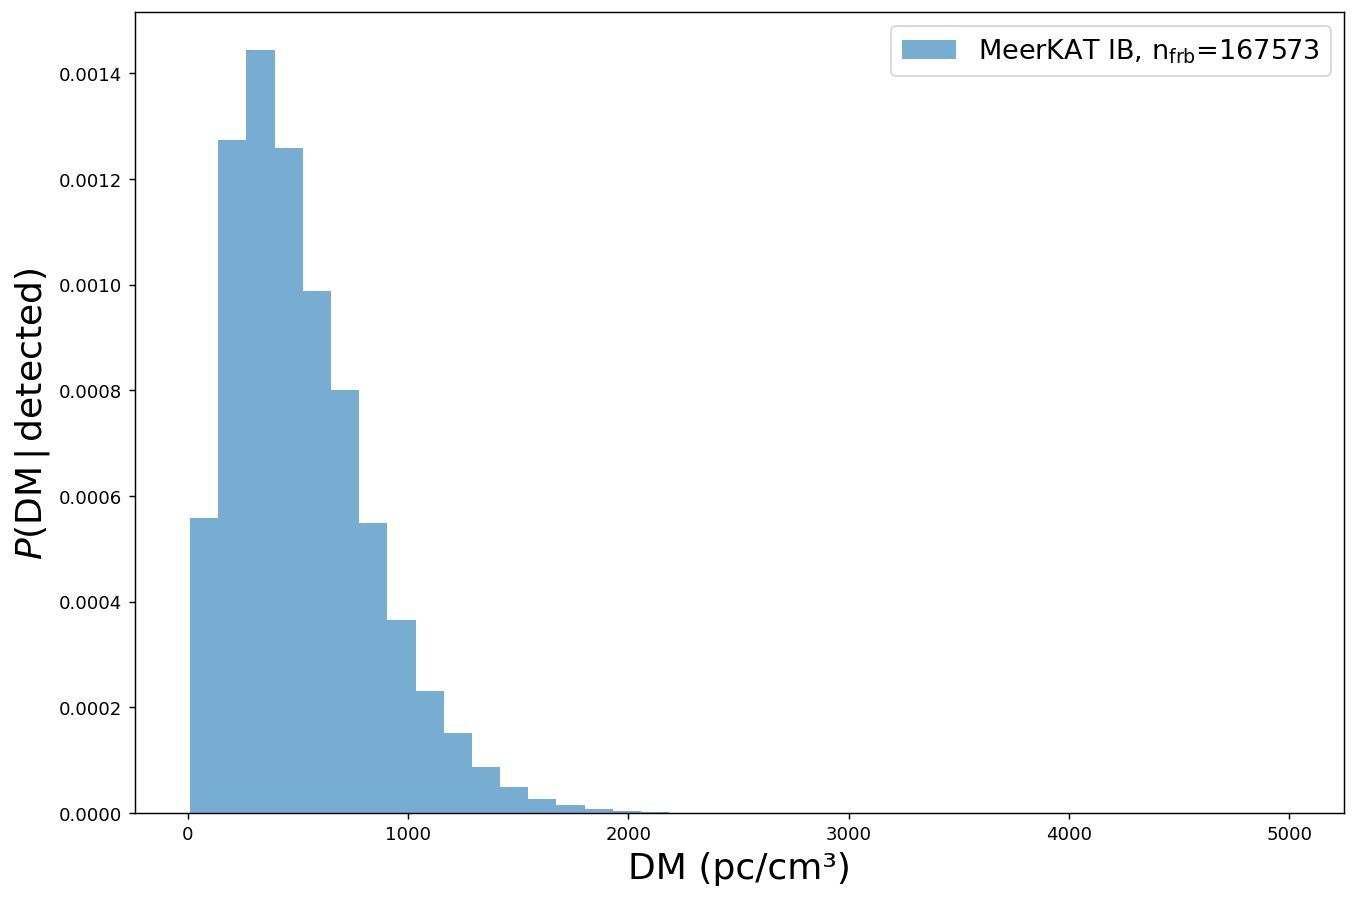

In [14]:
%matplotlib inline
# ----------------------------------------------------------------------------
# DM histogram (weighted population) for this telescope
# ----------------------------------------------------------------------------
results = all_results[TEL_KEY]
DMs  = np.array([r["DM"] for r in results])
pops = np.array([r["n_total_population"] for r in results])
nfrb = pops.sum()

fig, ax = plt.subplots(figsize=(12, 8), dpi=130)
bins = np.linspace(DMs.min(), DMs.max(), 40)
ax.hist(DMs, bins=bins, weights=pops, density=True, alpha=0.6, color=colors_tel[TEL_KEY],
        label=f'MeerKAT IB, n$_{{\\mathrm{{frb}}}}$={int(nfrb)}')
ax.set_xlabel("DM (pc/cm\u00b3)", fontsize=20)
ax.set_ylabel(r"$P(\mathrm{DM}\,|\,\mathrm{detected})$", fontsize=20)
ax.legend(fontsize=15)
plt.show()


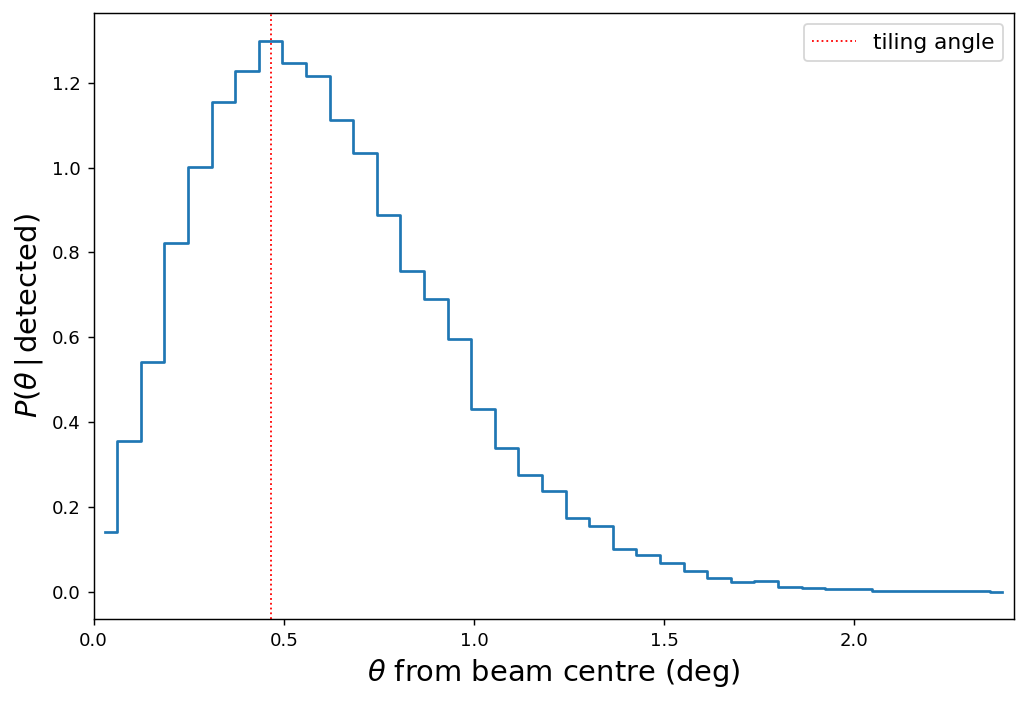

weighted median theta = 0.571 deg, 90% within 1.052 deg
half-power radius = 0.605 deg; fraction of weighted detections inside it: 54.3%


In [15]:
# ----------------------------------------------------------------------------
# Offset of detected FRBs from the beam centre (boresight)
# theta is recovered from the stored gain_ratio = exp(-C * theta^2 * nu0^2)
# ----------------------------------------------------------------------------
ev = fluence_dm_results[TEL_KEY]
gr = np.array([e["gain_ratio"] for e in ev])
w  = np.array([e["weight"] for e in ev])
THETA_TILING_DEG = 0.4668697
theta_rad = np.sqrt(-np.log(gr) / (_INNER_COEFF_CONST_new * nu0 ** 2))
theta_deg = np.degrees(theta_rad)

theta_hp_deg  = np.degrees(theta_hp)      # half-power radius at nu0 (gain = 0.5)
theta_cut_deg = 4.0 * theta_hp_deg        # angle_ok cut used in the simulation

fig, ax = plt.subplots(figsize=(8, 5.5), dpi=130)
bins = np.linspace(0, theta_cut_deg, 40)
h, edges = np.histogram(theta_deg, bins=bins, weights=w, density=True)
mid = 0.5 * (edges[1:] + edges[:-1])
ax.step(mid, h, where="mid", color=colors_tel[TEL_KEY])
# ax.axvline(theta_hp_deg, color="k", ls="--", lw=1, label="half-power radius")
ax.axvline(THETA_TILING_DEG, color="r", ls=":", lw=1, label="tiling angle")
ax.set_xlabel(r"$\theta$ from beam centre (deg)", fontsize=16)
ax.set_ylabel(r"$P(\theta\,|\,\mathrm{detected})$", fontsize=16)
ax.set_xlim(0, theta_cut_deg)
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()

order = np.argsort(theta_deg)
cdf = np.cumsum(w[order]) / w.sum()
print(f"weighted median theta = {np.interp(0.5, cdf, theta_deg[order]):.3f} deg, "
      f"90% within {np.interp(0.9, cdf, theta_deg[order]):.3f} deg")
print(f"half-power radius = {theta_hp_deg:.3f} deg; "
      f"fraction of weighted detections inside it: {100*w[theta_deg <= theta_hp_deg].sum()/w.sum():.1f}%")

In [16]:
# ----------------------------------------------------------------------------
# How many IB detections lie inside the MeerKAT CB tiling radius
# theta recovered from gain_ratio = exp(-C * theta^2 * nu0^2)
# ----------------------------------------------------------------------------
THETA_TILING_DEG = 0.4668697   # tiling radius used in the CB notebook (deg)

ev = fluence_dm_results[TEL_KEY]
gr = np.array([e["gain_ratio"] for e in ev])
w  = np.array([e["weight"] for e in ev])

theta_deg = np.degrees(np.sqrt(-np.log(gr) / (_INNER_COEFF_CONST_new * nu0 ** 2)))
inside = theta_deg < THETA_TILING_DEG

n_raw_tot, n_raw_in = len(gr), inside.sum()
n_w_tot,   n_w_in   = w.sum(), w[inside].sum()

print(f"Tiling radius            : {THETA_TILING_DEG:.4f} deg "
      f"(IB half-power radius at nu0 = {np.degrees(theta_hp):.3f} deg)")
print(f"Weighted (population)    : {n_w_in:.1f} / {n_w_tot:.1f} inside tiling ({100*n_w_in/n_w_tot:.1f}%)")
print(f"Weighted, outside        : {n_w_tot - n_w_in:.1f}")

Tiling radius            : 0.4669 deg (IB half-power radius at nu0 = 0.605 deg)
Weighted (population)    : 61202.1 / 167573.8 inside tiling (36.5%)
Weighted, outside        : 106371.7


In [17]:
# ----------------------------------------------------------------------------
# SAVE: DM distribution of the weighted population -> .npy
#
# Array shape (N, 2), one row per redshift bin that had detections:
#   column 0 = DM (pc/cm^3)          (= 1000 * z)
#   column 1 = n_total_population    (weighted number of FRBs in that bin)
# Weighted DM histogram: np.histogram(arr[:,0], bins=..., weights=arr[:,1]).
# ----------------------------------------------------------------------------
import os
OUT_DIR = "/home/thsu/FRB_population/DM_distribution"
os.makedirs(OUT_DIR, exist_ok=True)

dm_distribution = np.column_stack([DMs, pops])
out_path = os.path.join(OUT_DIR, "DM_distribution_meerkat_ib.npy")
np.save(out_path, dm_distribution)
print(f"Saved {dm_distribution.shape} array (DM, weighted population) -> {out_path}")
print(f"Total weighted population: {pops.sum():.1f}")


Saved (4990, 2) array (DM, weighted population) -> /home/thsu/FRB_population/DM_distribution/DM_distribution_meerkat_ib.npy
Total weighted population: 167573.8
